# Leave-one-condition-out cross-validation (LOOCV)

LOOCV asks whether the selected structure predicts a condition it has not seen. For each of the 22 conditions $h$ (RF03 included):

1. **Train** on the other 21 conditions: the full-data anchor restricted to them (theta, and the primal point of the 21 conditions) is the warm start of a refit with the tight options, then `refine_anchor`. The balanced-metabolite, cofactor and drain bounds are recomputed from the training conditions only and must contain the training data (no leak of the held-out measurements into the bounds).
2. **Fold status.** The anchor theta with per-condition re-optimised states is a feasible point of the fold problem, so the fold objective cannot exceed the *bound* $(\text{TOTAL} - \text{total}_h)/n_\text{train}$ of the objective breakdown. `anchor_ok`: $\text{obj}_\text{fold} \le \text{bound}\,(1 + 10^{-6})$; otherwise a multistart from the restricted anchor (`multistart_ok` if it reaches the bound, `above_bound` if not, typically because the anchor lies outside the training-only bounds).
3. **Predict** the held-out condition through the *closure*: with the fixed enzyme levels of $h$ the model needs $b$ and the cofactors; $\alpha$ = training mean of $b / v_\text{pts}$ (`pts_fraction`), $u_\text{ref}$ and $x_\text{ref}$ = geometric means of the fitted training states. The prediction of the held-out drains, fluxes and metabolites comes from solving the steady state with that closure.
4. **Baseline** = the training mean: metabolites, mean of the measured training values; fluxes, $S^{-1}\bar b$ with $\bar b$ the training-mean data.

The score is the RMSE of the model against the RMSE of the baseline over the held-out cells, and $R^2_\text{baseline} = 1 - \sum (y - \hat y)^2 / \sum (y - y_\text{base})^2$ (negative: the model is worse than predicting the training mean). The paper's LOOCV leaked the held-out fluxes through $b$; this one does not.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from settings import RUN as RUN_SETTINGS, default_params
from model.parameters import LI_FLUX_KEYS
from uncertainty import loocv

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

FINAL = os.path.join(OUT, "final")
LOO = os.path.join(OUT, "loocv")
N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. Run (`HK_RUN=1`)

`loocv.run_loocv_analysis(anchor_dir, out_dir, params)` loads the final point of `OUT/final` without a solve (`load_point`), runs the 22 folds in a process pool and writes `fold_status.csv`, `fold_theta.csv`, `loocv_pred.csv`, `loocv_real.csv`, `loocv_baseline.csv`, `loocv_b_implied.csv`, `loocv_per_output.csv`, `loocv_summary.json` and `loocv_summary.csv` into `OUT/loocv/`. The settings are the dict `params` below (defaults from `settings/uncertainty.csv` and `settings/thresholds.csv`); switch: `HK_N_JOBS`.

In [2]:
# Settings of the LOOCV (defaults from settings/uncertainty.csv and settings/thresholds.csv)
params = default_params("loocv")
params["loocv_n_starts"] = 10        # multistart size of a fold that does not reach its bound
params["loocv_bound_rtol"] = 1e-6    # a fold is anchor_ok if obj_fold <= bound (1 + this)
params["n_jobs"] = N_JOBS            # worker processes (HK_N_JOBS)
params

{'n_jobs': 8, 'loocv_bound_rtol': 1e-06, 'loocv_n_starts': 10}

In [3]:
if RUN:
    loocv.run_loocv_analysis(FINAL, LOO, params)
else:
    print("RUN is False: the LOOCV is loaded from", LOO)

[     1s] check_bounds_contain_data: OK (balanced, cofactors, drains); Pi bounds (1.0, 20.0)


[   165s] fold KO02: multistart_ok obj 11.44687 bound 11.45028


[   165s] fold KO03: above_bound obj 11.68235 bound 11.45416


[   165s] fold KO04: above_bound obj 12.18979 bound 11.45705


[   165s] fold KO05: above_bound obj 12.57650 bound 9.93187


[   165s] fold KO07: multistart_ok obj 11.38785 bound 11.41128


... (15 outputs left out)

[   165s] fold KO24: anchor_ok obj 11.12726 bound 11.16651


[   165s] fold RF03: anchor_ok obj 11.28530 bound 11.30134


[   165s] LOOCV summary: {'met_all_folds': {'rmse_model': 0.20354048292553586, 'rmse_baseline': 0.16585392771908736, 'r2_vs_baseline': -0.506087068092069, 'n': 103, 'n_folds': 22}, 'met_closure_success_only': {'rmse_model': 0.2197285730744283, 'rmse_baseline': 0.17567672182708738, 'r2_vs_baseline': -0.5643885664859263, 'n': 86, 'n_folds': 18}, 'flux_li_all_folds': {'rmse_model': 1.3763630971277276, 'rmse_baseline': 0.7616688041679471, 'r2_vs_baseline': -2.265379807164077, 'n': 110, 'n_folds': 22}, 'flux_li_closure_success_only': {'rmse_model': 1.4139864825768118, 'rmse_baseline': 0.8227624499052256, 'r2_vs_baseline': -1.9535313843565496, 'n': 90, 'n_folds': 18}, 'fold_status_counts': {'multistart_ok': 8, 'above_bound': 8, 'anchor_ok': 6}, 'n_anchor_outside_training_bounds': 11}


[   165s] 
       h    fold_status  obj_fold    bound  anchor_inside_training_bounds  n_anchor_values_outside_bounds  closure_success
0   KO02  multistart_ok   11.4469  11.4503                           True                               0             True
1   KO03    above_bound   11.6823  11.4542                          False                               1             True
2   KO04    above_bound   12.1898  11.4570                          False                              32             True
3   KO05    above_bound   12.5765   9.9319                          False                               3             True
4   KO07  multistart_ok   11.3879  11.4113                           True                               0             True
5   KO08  multistart_ok   11.3910  11.4173                          False                               3            False
6   KO10    above_bound   11.4418  11.4344                           True                               0             True
7   K

## 2. Folds

`bound` is the objective the fold must reach; `anchor_inside_training_bounds` is False when the full-data anchor lies outside the bounds recomputed from the training conditions (then the bound is unattainable and `above_bound` is expected); `closure_success` says whether the held-out closure solve converged.

In [4]:
def load_csv(name, **kw):
    path = os.path.join(LOO, name)
    return pd.read_csv(path, **kw) if os.path.exists(path) else None

folds = load_csv("fold_status.csv")
if folds is not None:
    print(folds["fold_status"].value_counts().to_dict())
    display(folds[["h", "fold_status", "obj_fold", "bound", "anchor_inside_training_bounds", "n_anchor_values_outside_bounds", "closure_success"]].set_index("h"))
else:
    print("loocv/fold_status.csv not found: run the LOOCV first")

{'multistart_ok': 8, 'above_bound': 8, 'anchor_ok': 6}


,fold_status,obj_fold,bound,anchor_inside_training_bounds,n_anchor_values_outside_bounds,closure_success
h,,,,,,
KO02,multistart_ok,11.446867,11.450281,True,0,True
KO03,above_bound,11.682350,11.454164,False,1,True
KO04,above_bound,12.189788,11.457045,False,32,True
KO05,above_bound,12.576501,9.931870,False,3,True
KO07,multistart_ok,11.387851,11.411281,True,0,True
KO08,multistart_ok,11.390966,11.417268,False,3,False
KO10,above_bound,11.441780,11.434448,True,0,True
KO11,anchor_ok,11.063635,11.065455,True,0,True
KO12,multistart_ok,11.414475,11.438180,True,0,True


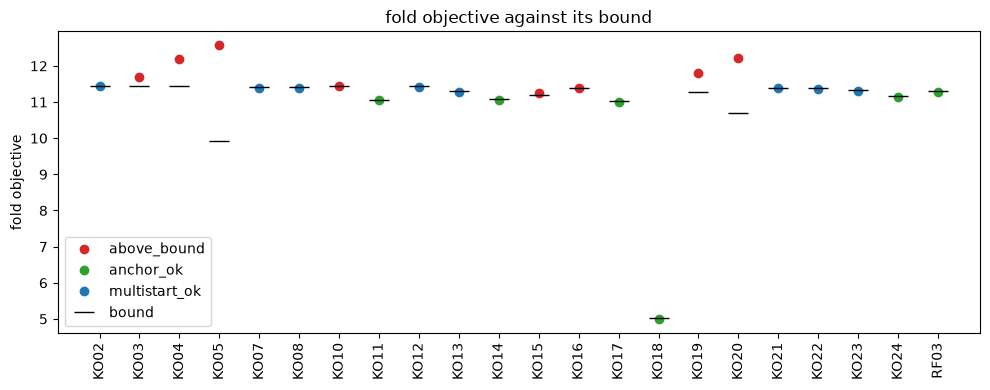

In [5]:
if folds is not None:
    colors = {"anchor_ok": "tab:green", "multistart_ok": "tab:blue", "above_bound": "tab:red"}
    fig, ax = plt.subplots(figsize=(10, 4))
    for status, grp in folds.groupby("fold_status"):
        ax.plot(grp.index, grp["obj_fold"], "o", color=colors.get(status, "grey"), label=status)
    ax.plot(folds.index, folds["bound"], "k_", ms=14, label="bound")
    ax.set_xticks(folds.index)
    ax.set_xticklabels(folds["h"], rotation=90)
    ax.set_ylabel("fold objective")
    ax.legend()
    ax.set_title("fold objective against its bound")
    fig.tight_layout()
    plt.show()

## 3. Held-out prediction against the baseline

`loocv_summary.json`: for the metabolites and the LI fluxes, over all folds and over the folds whose closure solve succeeded, the RMSE of the model, the RMSE of the training-mean baseline and $R^2$ against the baseline.

In [6]:
summary_path = os.path.join(LOO, "loocv_summary.json")
loo_summary = json.load(open(summary_path)) if os.path.exists(summary_path) else None
if loo_summary is not None:
    rows = {k: v for k, v in loo_summary.items() if isinstance(v, dict) and "rmse_model" in v}
    display(pd.DataFrame(rows).T)
    print("fold status:", loo_summary["fold_status_counts"], "| anchor outside the training bounds in", loo_summary["n_anchor_outside_training_bounds"], "folds")

,rmse_model,rmse_baseline,r2_vs_baseline,n,n_folds
met_all_folds,0.203540,0.165854,-0.506087,103.0,22.0
met_closure_success_only,0.219729,0.175677,-0.564389,86.0,18.0
flux_li_all_folds,1.376363,0.761669,-2.265380,110.0,22.0
flux_li_closure_success_only,1.413986,0.822762,-1.953531,90.0,18.0


fold status: {'multistart_ok': 8, 'above_bound': 8, 'anchor_ok': 6} | anchor outside the training bounds in 11 folds


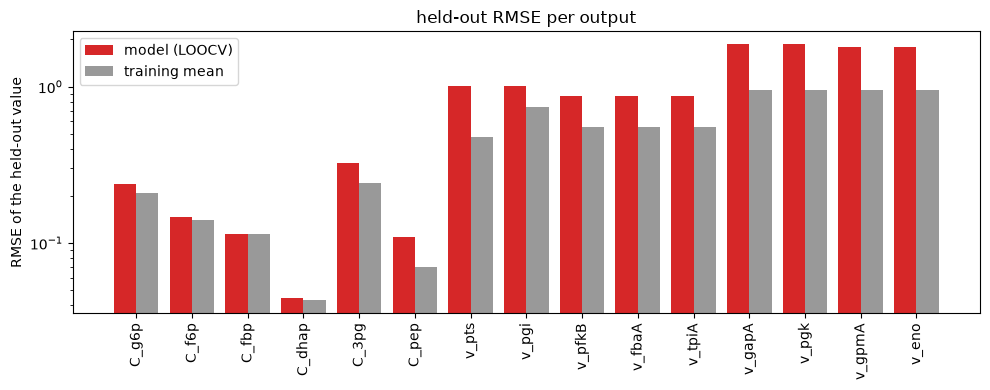

In [7]:
per_output = load_csv("loocv_per_output.csv", index_col=0)
if per_output is not None:
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(per_output))
    ax.bar(x - 0.2, per_output["rmse_model"], width=0.4, color="tab:red", label="model (LOOCV)")
    ax.bar(x + 0.2, per_output["rmse_baseline"], width=0.4, color="0.6", label="training mean")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(per_output.index, rotation=90)
    ax.set_ylabel("RMSE of the held-out value")
    ax.legend()
    ax.set_title("held-out RMSE per output")
    fig.tight_layout()
    plt.show()

### Parity of the held-out predictions

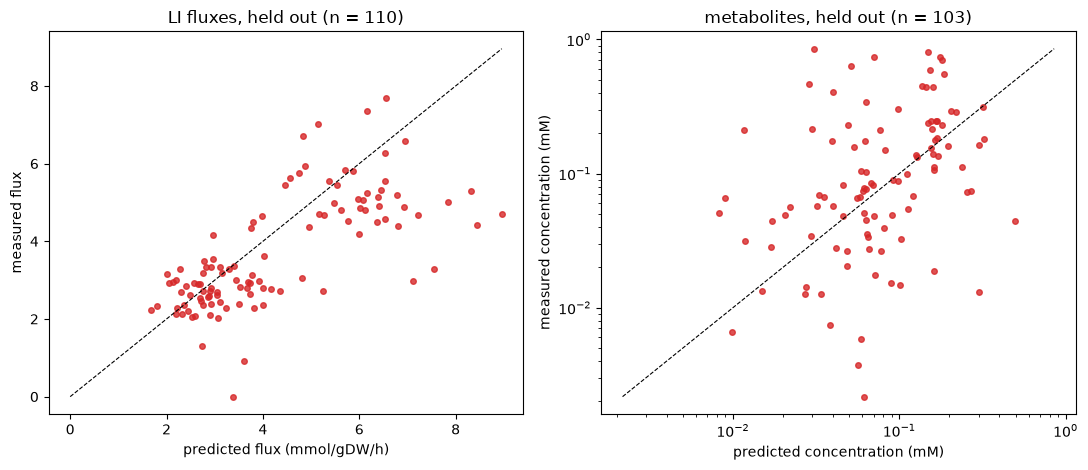

In [8]:
pred = load_csv("loocv_pred.csv", index_col=0)
real = load_csv("loocv_real.csv", index_col=0)
if pred is not None and real is not None:
    real = real.loc[pred.index, pred.columns]
    met_cols = [c for c in pred.columns if c.startswith("C_") and real[c].notna().any()]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    ax_flux, ax_met = axes

    # LI fluxes
    xf, yf = pred[LI_FLUX_KEYS].to_numpy(float).ravel(), real[LI_FLUX_KEYS].to_numpy(float).ravel()
    ok = np.isfinite(xf) & np.isfinite(yf)
    ax_flux.plot(xf[ok], yf[ok], "o", ms=4, color="tab:red", alpha=0.8)
    lims = [min(xf[ok].min(), yf[ok].min()), max(xf[ok].max(), yf[ok].max())]
    ax_flux.plot(lims, lims, "k--", lw=0.8)
    ax_flux.set_xlabel("predicted flux (mmol/gDW/h)")
    ax_flux.set_ylabel("measured flux")
    ax_flux.set_title("LI fluxes, held out (n = %d)" % ok.sum())

    # measured balanced metabolites, log-log
    xm, ym = pred[met_cols].to_numpy(float).ravel(), real[met_cols].to_numpy(float).ravel()
    ok = np.isfinite(xm) & np.isfinite(ym) & (xm > 0) & (ym > 0)
    ax_met.loglog(xm[ok], ym[ok], "o", ms=4, color="tab:red", alpha=0.8)
    lims = [min(xm[ok].min(), ym[ok].min()), max(xm[ok].max(), ym[ok].max())]
    ax_met.plot(lims, lims, "k--", lw=0.8)
    ax_met.set_xlabel("predicted concentration (mM)")
    ax_met.set_ylabel("measured concentration (mM)")
    ax_met.set_title("metabolites, held out (n = %d)" % ok.sum())

    fig.tight_layout()
    plt.show()